In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
cores_count = os.cpu_count()

In [3]:
from datetime import date, datetime, timedelta
from dateutil.rrule import rrule, DAILY

from matplotlib import pyplot
%matplotlib inline

import numpy as np
import pandas as pd

import scipy.stats as ss
from sklearn import linear_model
import statsmodels.api as sm

In [4]:
df_vitals = pd.read_csv('combined_vitals.csv')

In [5]:
#convert the timestamp field from string to datetime data type
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'],errors='coerce')

In [6]:
# keep only the required fields 
df_vitals=df_vitals[['patient_uuid','timestamp','HR','SBP','DBP']]

In [7]:
df_vitals.head()

,patient_uuid,timestamp,HR,SBP,DBP
0,82591262,2015-12-31 23:08:00,67.0,161.0,112.0
1,82591262,2018-10-09 13:40:00,80.0,111.0,72.0
2,82591262,2018-10-09 17:39:00,79.0,134.0,84.0
3,82591262,2018-10-09 17:40:00,79.0,126.0,79.0
4,82591262,2018-10-10 08:07:00,53.0,137.0,88.0


In [8]:
# remove entries older than 01-Oct-2018 and newer than 14-Jan-2020. This step may or may not be needed.
# retaining it as-is for now
df_vitals=df_vitals[(df_vitals.timestamp>'2018-10-01')&(df_vitals.timestamp<'2020-01-14')]

# remove all na entries
df_vitals=df_vitals[~df_vitals['DBP'].isna()]
df_vitals=df_vitals[~df_vitals['SBP'].isna()]
df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [9]:
# Let's start our analysis with the Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']]

In [10]:
df_vitals_sbp

,timestamp,patient_uuid,SBP
1,2018-10-09 13:40:00,82591262,111.0
2,2018-10-09 17:39:00,82591262,134.0
3,2018-10-09 17:40:00,82591262,126.0
4,2018-10-10 08:07:00,82591262,137.0
5,2018-10-10 14:02:00,82591262,134.0
...,...,...,...
340960,2020-01-10 08:27:00,81827529,119.0
340961,2020-01-10 12:46:00,81827529,115.0
340962,2020-01-11 07:39:00,81827529,113.0
340963,2020-01-13 08:47:00,81827529,97.0


In [11]:
df_vitals_sbp_day = df_vitals_sbp

df_vitals_sbp_day['reading_date'] = [dt.date() for dt in df_vitals_sbp_day.timestamp]

df_vitals_sbp_day['reading_date'] = pd.to_datetime(df_vitals_sbp_day['reading_date'])

df_vitals_sbp_day = df_vitals_sbp_day.groupby(['patient_uuid','reading_date']).filter(lambda x : len(x)>1)
df_vitals_sbp_day

,timestamp,patient_uuid,SBP,reading_date
1,2018-10-09 13:40:00,82591262,111.0,2018-10-09
2,2018-10-09 17:39:00,82591262,134.0,2018-10-09
3,2018-10-09 17:40:00,82591262,126.0,2018-10-09
4,2018-10-10 08:07:00,82591262,137.0,2018-10-10
5,2018-10-10 14:02:00,82591262,134.0,2018-10-10
...,...,...,...,...
340959,2020-01-08 12:06:00,81827529,137.0,2020-01-08
340960,2020-01-10 08:27:00,81827529,119.0,2020-01-10
340961,2020-01-10 12:46:00,81827529,115.0,2020-01-10
340963,2020-01-13 08:47:00,81827529,97.0,2020-01-13


In [12]:
df_vitals_sbp_day = pd.DataFrame(df_vitals_sbp_day.groupby(['patient_uuid','reading_date']).agg({'SBP' : np.mean}))
df_vitals_sbp_day = df_vitals_sbp_day.reset_index(level=[0,1])
df_vitals_sbp_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_sbp_day['source'] = 1

In [13]:
df_vitals_sbp_day

,patient_uuid,reading_date,SBP,source
0,1048697,2019-08-26,126.000000,1
1,1048697,2019-08-27,123.000000,1
2,1048697,2019-08-28,113.000000,1
3,1048697,2019-08-29,125.333333,1
4,1048697,2019-08-30,122.000000,1
...,...,...,...,...
95083,99726731,2019-03-18,130.000000,1
95084,99726731,2019-03-19,115.000000,1
95085,99726731,2019-03-21,147.000000,1
95086,99726731,2019-03-22,97.000000,1


In [14]:
# extend the dataset to have a new field 
# that contains the date time value of the very first measurement available for each patient
# this information will later be used to derive additional column values of interest

df_vitals_sbp_minmaxtimes = pd.DataFrame(df_vitals_sbp.groupby('patient_uuid').agg({'timestamp' : np.min}))
df_vitals_sbp_minmaxtimes['timestamp'] = df_vitals_sbp_minmaxtimes['timestamp']

df_vitals_sbp_extended = pd.merge(df_vitals_sbp, df_vitals_sbp_minmaxtimes, on='patient_uuid')
df_vitals_sbp_extended['reading_date'] = pd.to_datetime(df_vitals_sbp_extended['reading_date'])
df_vitals_sbp_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)

In [15]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y
0,2018-10-09 13:40:00,82591262,111.0,2018-10-09,2018-10-09 13:40:00
1,2018-10-09 17:39:00,82591262,134.0,2018-10-09,2018-10-09 13:40:00
2,2018-10-09 17:40:00,82591262,126.0,2018-10-09,2018-10-09 13:40:00
3,2018-10-10 08:07:00,82591262,137.0,2018-10-10,2018-10-09 13:40:00
4,2018-10-10 14:02:00,82591262,134.0,2018-10-10,2018-10-09 13:40:00
...,...,...,...,...,...
337912,2020-01-09 05:41:00,3959150,120.0,2020-01-09,2019-11-27 06:59:00
337913,2020-01-10 12:40:00,3959150,164.0,2020-01-10,2019-11-27 06:59:00
337914,2020-01-10 22:17:00,3959150,135.0,2020-01-10,2019-11-27 06:59:00
337915,2020-01-11 04:44:00,3959150,138.0,2020-01-11,2019-11-27 06:59:00


In [16]:
# In the extended dataset, add two additional columns that have the measurement date (without the time)
# and the start date (without the time)
# Again, this information will be used subsequently to derive additional features of interest
df_vitals_sbp_extended['reading_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_x]
df_vitals_sbp_extended['reading_date'] = pd.to_datetime(df_vitals_sbp_extended['reading_date'])
df_vitals_sbp_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_sbp_extended['reading_start_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_y]
df_vitals_sbp_extended['reading_start_date'] = pd.to_datetime(df_vitals_sbp_extended['reading_start_date'])

In [17]:
# for every reading, get the days elapsed since the first measurement date (note this is in days)
df_vitals_sbp_extended['days_elapsed'] = (df_vitals_sbp_extended['reading_date'] - df_vitals_sbp_extended['reading_start_date']).dt.days
df_vitals_sbp_extended['log_days_elapsed'] = np.log(df_vitals_sbp_extended['days_elapsed'])/10
df_vitals_sbp_extended.loc[df_vitals_sbp_extended.days_elapsed == 0,'log_days_elapsed'] = 0

In [18]:
# convert the new time stamp columns to date time data type
df_vitals_sbp_extended['timestamp_x'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_x'])
df_vitals_sbp_extended['timestamp_y'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_y'])

In [19]:
# Now, from the time component, get the hours since mid night for each measurement
# and extend it further to get the corresponding angle (24 hours = 360 degress, x hours = x*360/24)

df_vitals_sbp_extended['elapsed_time'] = df_vitals_sbp_extended['timestamp_x'] - df_vitals_sbp_extended['reading_date']
df_vitals_sbp_extended['angle'] = df_vitals_sbp_extended['elapsed_time'].diff() *360 / (np.timedelta64(1, 'h') *24)

# get the cosine and sine values corresponding to these angles
df_vitals_sbp_extended['sine'] = np.sin(df_vitals_sbp_extended['angle'])
df_vitals_sbp_extended['cos'] = np.cos(df_vitals_sbp_extended['angle'])

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos'].isna()]


# get the cosine and sine values corresponding to the angles with a period T/2 = 12 hours
df_vitals_sbp_extended['sine.Tby2'] = np.sin(df_vitals_sbp_extended['angle']*2)
df_vitals_sbp_extended['cos.Tby2'] = np.cos(df_vitals_sbp_extended['angle']*2)

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine.Tby2'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos.Tby2'].isna()]

# get the cosine and sine values corresponding to the angles with a period T/3 = 8 hours
df_vitals_sbp_extended['sine.Tby3'] = np.sin(df_vitals_sbp_extended['angle']*3)
df_vitals_sbp_extended['cos.Tby3'] = np.cos(df_vitals_sbp_extended['angle']*3)

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine.Tby3'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos.Tby3'].isna()]

# get the cosine and sine values corresponding to the angles with a period T/6 = 4 hours
df_vitals_sbp_extended['sine.Tby6'] = np.sin(df_vitals_sbp_extended['angle']*6)
df_vitals_sbp_extended['cos.Tby6'] = np.cos(df_vitals_sbp_extended['angle']*6)

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine.Tby6'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos.Tby6'].isna()]

In [20]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,log_days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,sine.Tby3,cos.Tby3,sine.Tby6,cos.Tby6
40074,2019-08-26 15:09:00,1048697,126.0,2019-08-26,2019-08-26 15:09:00,2019-08-26,0,0.000000,15:09:00,0.00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
40011,2019-08-27 07:09:00,1048697,127.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,07:09:00,-120.00,-0.580611,0.814181,-0.945445,0.325781,-0.958916,-0.283691,0.544072,-0.839039
40012,2019-08-27 16:49:00,1048697,128.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,16:49:00,145.00,0.467745,0.883863,0.826846,0.562429,0.993892,0.110357,0.219366,-0.975643
40013,2019-08-27 19:49:00,1048697,114.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,19:49:00,45.00,0.850904,0.525322,0.893997,-0.448074,0.088369,-0.996088,-0.176046,0.984382
40075,2019-08-27 07:09:00,1048697,127.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,07:09:00,-190.00,-0.997799,0.066307,-0.132322,-0.991207,0.980252,-0.197754,-0.387698,-0.921786
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330469,2020-01-11 11:26:00,99814066,131.0,2020-01-11,2020-01-08 11:17:00,2020-01-08,3,0.109861,11:26:00,5.50,-0.705540,0.708670,-0.999990,0.004426,-0.711785,-0.702397,0.999912,-0.013277
330470,2020-01-12 12:18:00,99814066,134.0,2020-01-12,2020-01-08 11:17:00,2020-01-08,4,0.138629,12:18:00,13.00,0.420167,0.907447,0.762558,0.646919,0.963795,0.266643,0.513978,-0.857803
330471,2020-01-13 11:03:00,99814066,143.0,2020-01-13,2020-01-08 11:17:00,2020-01-08,5,0.160944,11:03:00,-18.75,0.099392,0.995048,0.197799,0.980243,0.294247,0.955729,0.562441,0.826837
130154,2019-05-07 10:28:00,99974875,143.0,2019-05-07,2019-05-07 10:28:00,2019-05-07,0,0.000000,10:28:00,-8.75,-0.624724,-0.780846,0.975626,0.219440,-0.898903,0.438148,-0.787705,-0.616052


In [21]:
# create a new column and extract the information on days between the current measurement and the previous measurement
df_vitals_sbp_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_sbp_extended['days_between_readings'] = -999

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

In [22]:
# review this data for one patient just to make sure that the derived columns have the correct values
df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == 82591262]

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,log_days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,sine.Tby3,cos.Tby3,sine.Tby6,cos.Tby6,days_between_readings
0,2018-10-09 13:40:00,82591262,111.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0.000000,13:40:00,-12.25,0.311119,0.950371,0.591358,0.806409,0.812899,0.582405,0.946873,-0.321608,NaN
1,2018-10-09 17:39:00,82591262,134.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0.000000,17:39:00,59.75,-0.059704,-0.998216,0.119195,0.992871,-0.178261,-0.983983,0.350811,0.936446,0.0
2,2018-10-09 17:40:00,82591262,126.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0.000000,17:40:00,0.25,0.247404,0.968912,0.479426,0.877583,0.681639,0.731689,0.997495,0.070737,0.0
53,2018-10-09 13:40:00,82591262,111.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0.000000,13:40:00,-60.00,0.304811,-0.952413,-0.580611,0.814181,0.801153,-0.598460,-0.958916,-0.283691,0.0
54,2018-10-09 17:39:00,82591262,134.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0.000000,17:39:00,59.75,-0.059704,-0.998216,0.119195,0.992871,-0.178261,-0.983983,0.350811,0.936446,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51,2018-12-02 17:14:00,82591262,111.0,2018-12-02,2018-10-09 13:40:00,2018-10-09,54,0.398898,17:14:00,160.00,0.219425,-0.975629,-0.428155,0.903705,0.616017,-0.787733,-0.970513,0.241047,0.0
103,2018-12-02 06:34:00,82591262,170.0,2018-12-02,2018-10-09 13:40:00,2018-10-09,54,0.398898,06:34:00,-160.00,-0.219425,-0.975629,0.428155,0.903705,-0.616017,-0.787733,0.970513,0.241047,0.0
104,2018-12-02 17:14:00,82591262,111.0,2018-12-02,2018-10-09 13:40:00,2018-10-09,54,0.398898,17:14:00,160.00,0.219425,-0.975629,-0.428155,0.903705,0.616017,-0.787733,-0.970513,0.241047,0.0
52,2018-12-04 12:41:00,82591262,137.0,2018-12-04,2018-10-09 13:40:00,2018-10-09,56,0.402535,12:41:00,-68.25,0.761120,0.648611,0.987342,-0.158608,0.519681,-0.854360,-0.887990,0.459863,2.0


In [23]:
# Now, we will split the measurements for each patients into multiple batches
# the batch contains successive measurements with a gap of no more than 3 days between two readings
# If the gap is higher, then there could be a big change that will throw off the interpolation
# the 3 here is a hyperparameter which may need to be tuned
df_vitals_sbp_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_sbp_extended['batch'] = 0

df_vitals_sbp_extended.loc[df_vitals_sbp_extended['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'batch'] = df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['batch'].cumsum()

In [24]:
df_vitals_sbp_extended.head(600)

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,log_days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,sine.Tby3,cos.Tby3,sine.Tby6,cos.Tby6,days_between_readings,batch
40074,2019-08-26 15:09:00,1048697,126.0,2019-08-26,2019-08-26 15:09:00,2019-08-26,0,0.000000,15:09:00,0.00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,NaN,0
40011,2019-08-27 07:09:00,1048697,127.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,07:09:00,-120.00,-0.580611,0.814181,-0.945445,0.325781,-0.958916,-0.283691,0.544072,-0.839039,1.0,0
40012,2019-08-27 16:49:00,1048697,128.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,16:49:00,145.00,0.467745,0.883863,0.826846,0.562429,0.993892,0.110357,0.219366,-0.975643,0.0,0
40013,2019-08-27 19:49:00,1048697,114.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,19:49:00,45.00,0.850904,0.525322,0.893997,-0.448074,0.088369,-0.996088,-0.176046,0.984382,0.0,0
40075,2019-08-27 07:09:00,1048697,127.0,2019-08-27,2019-08-26 15:09:00,2019-08-26,1,0.000000,07:09:00,-190.00,-0.997799,0.066307,-0.132322,-0.991207,0.980252,-0.197754,-0.387698,-0.921786,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170554,2019-11-01 17:30:00,1193821,100.0,2019-11-01,2019-10-22 12:14:00,2019-10-22,10,0.230259,17:30:00,84.50,0.317414,-0.948287,-0.602000,0.798496,0.824323,-0.566120,-0.933331,-0.359016,0.0,0
170579,2019-11-01 11:52:00,1193821,113.0,2019-11-01,2019-10-22 12:14:00,2019-10-22,10,0.230259,11:52:00,-84.50,-0.317414,-0.948287,0.602000,0.798496,-0.824323,-0.566120,0.933331,-0.359016,0.0,0
170580,2019-11-01 17:30:00,1193821,100.0,2019-11-01,2019-10-22 12:14:00,2019-10-22,10,0.230259,17:30:00,84.50,0.317414,-0.948287,-0.602000,0.798496,0.824323,-0.566120,-0.933331,-0.359016,0.0,0
170555,2019-11-02 10:19:00,1193821,123.0,2019-11-02,2019-10-22 12:14:00,2019-10-22,11,0.239790,10:19:00,-107.75,-0.805103,0.593134,-0.955069,-0.296383,-0.327866,-0.944724,0.619485,0.785008,1.0,0


Y = M + a * cos(theta) + b * sin(theta) + c * cos(theta*2) + d * sin(theta*2) + e * cos(theta*3) + f * sin(theta*2) + g * cos(theta*6) + h * sin(theta*6) + i*log(days_elapsed)

To identify the median, we find the min and max, which happens when:

d/dt [a*cos(t) + b*sin(t)] = 0

-a*sin(t)+b*cos(t) = 0

a*sin(t)=b*cos(t)

tan(t) = b/a

t = taninv(b/a)

Y(max) for a given day = M + Max(x+y) + B

Y(min) for a given day = M + Min(x+y) + B

Here x=a*cos(t), y = b*sin(t), B = c*days_elapsed

Note, B varies over days due to days_elapsed

So, Ymedian for a day = [Max(x+y)+Min(x+y)]/2 + c*days_elapsed, which is also equal to M+Min(x+y)

Note, Median may not be equal to intercept since intercept in this case is only ...although for simplicity we can just go with the intercept





In [25]:
# the mathematical expression for the model is: 
# Y = M + a * cos(theta) + b * sin(theta) + c * cos(theta*2) + d * sin(theta*2) + e * cos(theta*3) + f * sin(theta*2) + g * cos(theta*6) + h * sin(theta*6) + i*days_elapsed
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
df_vitals_interpolated = pd.DataFrame(columns = ['patient_uuid','reading_date','SBP'])
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date'])
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'], inplace=True)
loopcount = len(df_vitals_sbp_extended['patient_uuid'].unique())
currloop = 0
for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    print(str(currloop) + ' out of ' + str(loopcount) + ', patient_uuid = ' + str(patient_uuid) )
    currloop = currloop + 1
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        df_vitals_subset_batch['reading_date'] = pd.to_datetime(df_vitals_subset_batch['reading_date'])
        df_vitals_subset_batch.sort_values(by=['patient_uuid','reading_date'],inplace=True)
        #if df_vitals_subset_batch.shape[0] > 1:
        X = df_vitals_subset_batch[['cos','sine','cos.Tby2','sine.Tby2','days_elapsed']]
        y = df_vitals_subset_batch[['SBP']]
        lm = linear_model.LinearRegression(n_jobs=cores_count)
        model = lm.fit(X,y)
        #print(df_vitals_subset_batch.agg({'reading_date' : np.min}))
        min_batch_date = pd.to_datetime(df_vitals_subset_batch.agg({'reading_date' : np.min}))
        max_batch_date = pd.to_datetime(df_vitals_subset_batch.agg({'reading_date' : np.max}))
        total_days = int((max_batch_date - min_batch_date).to_string().split(' ')[3])
        for days_elapsed in np.arange(0,total_days,1):
            SBP_interpolated = float(lm.intercept_) + float(lm.coef_[0][4]) * days_elapsed
            reading_date = pd.to_datetime((min_batch_date + pd.DateOffset(days=days_elapsed)).to_string().split('   ')[1])
            #print(reading_date)
            df_vitals_interpolated.loc[len(df_vitals_interpolated)] = [patient_uuid, reading_date, SBP_interpolated]
            days_elapsed = days_elapsed + 1
            
        #break
    #break
print('Interpolation Procedure completed')

0 out of 1626, patient_uuid = 1048697
1 out of 1626, patient_uuid = 1127912
2 out of 1626, patient_uuid = 1164638
3 out of 1626, patient_uuid = 1166047
4 out of 1626, patient_uuid = 1193821
5 out of 1626, patient_uuid = 1231804
6 out of 1626, patient_uuid = 1386626
7 out of 1626, patient_uuid = 1425812
8 out of 1626, patient_uuid = 1519674
9 out of 1626, patient_uuid = 1523219
10 out of 1626, patient_uuid = 1712654
11 out of 1626, patient_uuid = 1944581
12 out of 1626, patient_uuid = 2075791
13 out of 1626, patient_uuid = 2096100
14 out of 1626, patient_uuid = 2104097
15 out of 1626, patient_uuid = 2132729
16 out of 1626, patient_uuid = 2168037
17 out of 1626, patient_uuid = 2172350
18 out of 1626, patient_uuid = 2254113
19 out of 1626, patient_uuid = 2372778
20 out of 1626, patient_uuid = 2453401
21 out of 1626, patient_uuid = 2469101
22 out of 1626, patient_uuid = 2555802
23 out of 1626, patient_uuid = 2617380
24 out of 1626, patient_uuid = 2714491
25 out of 1626, patient_uuid = 2763

In [26]:
df_vitals_sbp_day = pd.merge(df_vitals_sbp_day, df_vitals_interpolated,on=['patient_uuid','reading_date'],how='inner')

In [28]:
df_vitals_sbp_day = df_vitals_sbp_day[['patient_uuid','reading_date','SBP_x']]

df_vitals_sbp_day.rename(columns={'SBP_x':'SBP'},inplace=True)

df_vitals_sbp_day

,patient_uuid,reading_date,SBP
0,1048697,2019-08-26,126.000000
1,1048697,2019-08-27,123.000000
2,1048697,2019-08-28,113.000000
3,1048697,2019-08-29,125.333333
4,1048697,2019-08-30,122.000000
...,...,...,...
93629,99726731,2019-03-16,123.333333
93630,99726731,2019-03-18,130.000000
93631,99726731,2019-03-19,115.000000
93632,99726731,2019-03-21,147.000000


In [29]:
print(df_vitals_interpolated.shape)

df_vitals_interpolated.to_csv("vitals_sbp_interpolated_dataset.csv", index = False)

(152508, 3)


In [30]:
df_vitals_interpolated = pd.read_csv('vitals_sbp_interpolated_dataset.csv')

In [ ]:
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date'])

df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'],inplace=True)

df_vitals_interpolated_minmaxtimes = pd.DataFrame(df_vitals_interpolated.groupby('patient_uuid').agg({'reading_date' : np.min}))

df_vitals_interpolated_minmaxtimes.rename(columns={'reading_date':'reading_start_date'},inplace=True)

df_vitals_interpolated_final = pd.merge(df_vitals_interpolated, df_vitals_interpolated_minmaxtimes, on='patient_uuid')

df_vitals_interpolated_final['reading_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_date'])

df_vitals_interpolated_final.sort_values(by=['patient_uuid','reading_date'],inplace=True)

df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days

df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 1,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','HR']]

In [ ]:
df_vitals_interpolated = df_vitals_interpolated_final

In [ ]:
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in df_vitals_interpolated['patient_uuid'].unique():
    vitals_sbp_interpolated_patient = df_vitals_interpolated[df_vitals_interpolated['patient_uuid']==patient_uuid]
    for batch in vitals_sbp_interpolated_patient['batch'].unique():
        vitals_sbp_interpolated_patient_batch = vitals_sbp_interpolated_patient[vitals_sbp_interpolated_patient['batch']==batch]
        vitals_sbp_interpolated_patient_batch['reading_date'] = pd.to_datetime(vitals_sbp_interpolated_patient_batch['reading_date'])
        vitals_sbp_interpolated_patient_batch['next_reading_date'] = vitals_sbp_interpolated_patient_batch['reading_date'].shift(-1)
        #print(int((vitals_sbp_interpolated_patient_batch['next_reading_date'] - vitals_sbp_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
        vitals_sbp_interpolated_patient_batch['days_difference'] = (vitals_sbp_interpolated_patient_batch['next_reading_date'] - vitals_sbp_interpolated_patient_batch['reading_date'])
        #print(vitals_sbp_interpolated_patient_batch.dtypes)
        row_count_with_days_diff = vitals_sbp_interpolated_patient_batch[vitals_sbp_interpolated_patient_batch['days_difference']>timedelta(days=1)].shape[0]
        if row_count_with_days_diff > 0:
            print(vitals_sbp_interpolated_patient_batch[vitals_sbp_interpolated_patient_batch['days_difference']>timedelta(days=1)])
    #break

In [31]:
#df_vitals_interpolated = df_vitals_interpolated[(df_vitals_interpolated.HR>0)]
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_interpolated['source'] = 2

df_vitals_interpolated = df_vitals_interpolated[['patient_uuid','reading_date','SBP','source']]
df_vitals_interpolated

,patient_uuid,reading_date,SBP,source
0,1048697,2019-08-26,113.143262,2
1,1048697,2019-08-27,113.209612,2
2,1048697,2019-08-28,113.275961,2
3,1048697,2019-08-29,113.342311,2
4,1048697,2019-08-30,113.408660,2
...,...,...,...,...
152503,99814066,2020-01-08,112.820825,2
152504,99814066,2020-01-09,110.853570,2
152505,99814066,2020-01-10,108.886316,2
152506,99814066,2020-01-11,106.919062,2


In [33]:
#df_vitals_hr_day = df_vitals_hr_day.reset_index(level=[0])
df_vitals_sbp_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_sbp_day['source'] = 1
df_vitals_sbp_day

,patient_uuid,reading_date,SBP,source
0,1048697,2019-08-26,126.000000,1
1,1048697,2019-08-27,123.000000,1
2,1048697,2019-08-28,113.000000,1
3,1048697,2019-08-29,125.333333,1
4,1048697,2019-08-30,122.000000,1
...,...,...,...,...
93629,99726731,2019-03-16,123.333333,1
93630,99726731,2019-03-18,130.000000,1
93631,99726731,2019-03-19,115.000000,1
93632,99726731,2019-03-21,147.000000,1


In [34]:
print(df_vitals_sbp_day.shape)

print(df_vitals_interpolated.shape)

(93634, 4)
(152508, 4)


In [35]:
df_vitals_interpolated

,patient_uuid,reading_date,SBP,source
0,1048697,2019-08-26,113.143262,2
1,1048697,2019-08-27,113.209612,2
2,1048697,2019-08-28,113.275961,2
3,1048697,2019-08-29,113.342311,2
4,1048697,2019-08-30,113.408660,2
...,...,...,...,...
152503,99814066,2020-01-08,112.820825,2
152504,99814066,2020-01-09,110.853570,2
152505,99814066,2020-01-10,108.886316,2
152506,99814066,2020-01-11,106.919062,2


In [36]:
df_vitals_sbp_day.patient_uuid = df_vitals_sbp_day.patient_uuid.astype(int)
df_vitals_sbp_day.SBP = df_vitals_sbp_day.SBP.astype(float)
df_vitals_sbp_day.source = df_vitals_sbp_day.source.astype(int)
df_vitals_sbp_day['reading_date'] = pd.to_datetime(df_vitals_sbp_day['reading_date']) 

df_vitals_interpolated.patient_uuid = df_vitals_interpolated.patient_uuid.astype(int)
df_vitals_interpolated.SBP = df_vitals_interpolated.SBP.astype(float)
df_vitals_interpolated.source = df_vitals_interpolated.source.astype(int)
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date']) 

In [37]:
df_vitals_interpolated.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
SBP                    float64
source                   int32
dtype: object

In [38]:
df_vitals_sbp_day.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
SBP                    float64
source                   int32
dtype: object

In [39]:
df_vitals_interpolated_new_values = pd.merge(df_vitals_sbp_day, df_vitals_interpolated,on=['patient_uuid','reading_date'],how='right')

In [40]:
df_vitals_interpolated_new_values=df_vitals_interpolated_new_values[(df_vitals_interpolated_new_values['SBP_x'].isna())|(df_vitals_interpolated_new_values['source_x'].isna())]

df_vitals_interpolated_new_values = df_vitals_interpolated_new_values[['patient_uuid','reading_date','SBP_y']]

In [41]:
df_vitals_interpolated_new_values.shape

(58874, 3)

In [42]:
df_vitals_interpolated[df_vitals_interpolated['patient_uuid']==82591262]

,patient_uuid,reading_date,SBP,source
126277,82591262,2018-10-09,136.311091,2
126278,82591262,2018-10-10,136.559416,2
126279,82591262,2018-10-11,136.807740,2
126280,82591262,2018-10-12,137.056065,2
126281,82591262,2018-10-13,137.304389,2
126282,82591262,2018-10-14,137.552714,2
126283,82591262,2018-10-15,137.801038,2
126284,82591262,2018-10-16,138.049363,2
126285,82591262,2018-10-17,138.297687,2
126286,82591262,2018-10-18,138.546012,2


In [ ]:
df_vitals_interpolated_new_values[df_vitals_interpolated_new_values['patient_uuid']==82591262]

In [ ]:
df_vitals_sbp_day[df_vitals_sbp_day['patient_uuid']==82591262]

In [43]:
df_vitals_sbp_day = df_vitals_sbp_day[['patient_uuid','reading_date','SBP']]

df_vitals_interpolated_new_values.rename(columns={"SBP_y":"SBP"},inplace=True)

In [44]:
df_vitals_interpolated_final = pd.concat([df_vitals_sbp_day,df_vitals_interpolated_new_values])

In [45]:
df_vitals_interpolated_final.shape

(152508, 3)

In [ ]:
df_vitals_interpolated_new_values[df_vitals_interpolated_new_values['patient_uuid']==82591262]

In [46]:
df_vitals_interpolated_final['reading_start_date'] = [dt.date() for dt in df_vitals_interpolated_final.reading_date]
df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days


df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)



df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 1,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','SBP']]

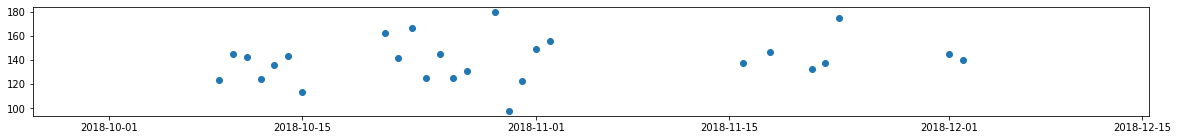

In [47]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_subset = df_vitals_sbp_day[df_vitals_sbp_day['patient_uuid'] == 82591262]
df_vitals_subset = df_vitals_subset[['reading_date','SBP']]
pyplot.scatter(df_vitals_subset['reading_date'],df_vitals_subset['SBP'])
pyplot.show()

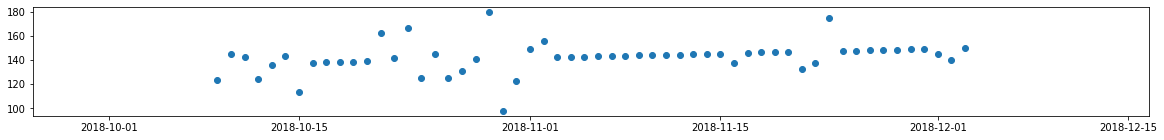

In [48]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_interpolated_subset = df_vitals_interpolated_final[df_vitals_interpolated_final['patient_uuid'] == 82591262]
df_vitals_interpolated_subset = df_vitals_interpolated_subset[['reading_date','SBP']]
pyplot.scatter(df_vitals_interpolated_subset['reading_date'],df_vitals_interpolated_subset['SBP'])
pyplot.show()

In [49]:
df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','SBP']]

In [50]:
df_vitals_sbp_minmaxtimes = pd.DataFrame(df_vitals_interpolated_final.groupby('patient_uuid').agg({'reading_date' : np.min}))

df_vitals_sbp_minmaxtimes.rename(columns={'reading_date':'reading_start_date'},inplace=True)

df_vitals_interpolated_final = pd.merge(df_vitals_interpolated_final, df_vitals_sbp_minmaxtimes, on='patient_uuid')

df_vitals_interpolated_final['reading_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_date'])
df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final.sort_values(by=['patient_uuid','reading_date'],inplace=True)


df_vitals_interpolated_final

,patient_uuid,reading_date,SBP,reading_start_date
0,1048697,2019-08-26,126.000000,2019-08-26
1,1048697,2019-08-27,123.000000,2019-08-26
2,1048697,2019-08-28,113.000000,2019-08-26
3,1048697,2019-08-29,125.333333,2019-08-26
4,1048697,2019-08-30,122.000000,2019-08-26
...,...,...,...,...
152503,99814066,2020-01-08,112.820825,2020-01-08
152504,99814066,2020-01-09,110.853570,2020-01-08
152505,99814066,2020-01-10,108.886316,2020-01-08
152506,99814066,2020-01-11,106.919062,2020-01-08


In [51]:
df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days


In [52]:
df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','SBP']]

In [53]:
df_vitals_interpolated_final.to_csv("vitals_sbp_interpolated.csv", index = False)

In [54]:
vitals_sbp_interpolated = pd.read_csv('vitals_sbp_interpolated.csv')

In [55]:
vitals_sbp_interpolated['reading_date'] = pd.to_datetime(vitals_sbp_interpolated['reading_date'])
vitals_sbp_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in vitals_sbp_interpolated['patient_uuid'].unique():
    vitals_sbp_interpolated_patient = vitals_sbp_interpolated[vitals_sbp_interpolated['patient_uuid']==patient_uuid]
    for batch in vitals_sbp_interpolated_patient['batch'].unique():
        vitals_sbp_interpolated_patient_batch = vitals_sbp_interpolated_patient[vitals_sbp_interpolated_patient['batch']==batch]
        vitals_sbp_interpolated_patient_batch['reading_date'] = pd.to_datetime(vitals_sbp_interpolated_patient_batch['reading_date'])
        vitals_sbp_interpolated_patient_batch['next_reading_date'] = vitals_sbp_interpolated_patient_batch['reading_date'].shift(-1)
        #print(int((vitals_sbp_interpolated_patient_batch['next_reading_date'] - vitals_sbp_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
        vitals_sbp_interpolated_patient_batch['days_difference'] = (vitals_sbp_interpolated_patient_batch['next_reading_date'] - vitals_sbp_interpolated_patient_batch['reading_date'])
        #print(vitals_sbp_interpolated_patient_batch.dtypes)
        row_count_with_days_diff = vitals_sbp_interpolated_patient_batch[vitals_sbp_interpolated_patient_batch['days_difference']>timedelta(days=1)].shape[0]
        if row_count_with_days_diff > 0:
            print(vitals_sbp_interpolated_patient_batch[vitals_sbp_interpolated_patient_batch['days_difference']>timedelta(days=1)])
    #break

In [ ]:
vitals_sbp_interpolated['reading_date'] = pd.to_datetime(vitals_sbp_interpolated['reading_date'])
vitals_sbp_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in vitals_sbp_interpolated['patient_uuid'].unique():
    vitals_sbp_interpolated_patient = vitals_sbp_interpolated[vitals_sbp_interpolated['patient_uuid']==patient_uuid]
    vitals_sbp_interpolated_patient['reading_date'] = pd.to_datetime(vitals_sbp_interpolated_patient['reading_date'])
    vitals_sbp_interpolated_patient['next_reading_date'] = vitals_sbp_interpolated_patient['reading_date'].shift(-1)
    #print(int((vitals_sbp_interpolated_patient_batch['next_reading_date'] - vitals_sbp_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
    vitals_sbp_interpolated_patient['days_difference'] = (vitals_sbp_interpolated_patient['next_reading_date'] - vitals_sbp_interpolated_patient['reading_date'])
    #print(vitals_sbp_interpolated_patient_batch.dtypes)
    row_count_with_days_diff = vitals_sbp_interpolated_patient[(vitals_sbp_interpolated_patient['days_difference']>timedelta(days=1))&(vitals_sbp_interpolated_patient['days_difference']<timedelta(days=16))].shape[0]
    if row_count_with_days_diff > 0:
        print(vitals_sbp_interpolated_patient[(vitals_sbp_interpolated_patient['days_difference']>timedelta(days=1))&(vitals_sbp_interpolated_patient['days_difference']<timedelta(days=16))])
    #break